# Causal Graph Estimation and 2D Visualization

This notebook estimates a causal graph with `SkeletonOrderDAGBuilder`, draws it at user-specified 2D coordinates, computes per-variable network metrics, and assesses edge stability with the bootstrap.

**Input data.** To analyse your own data, place it in these files or change the paths in `CONFIG`.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from functions import (
    bootstrap,
    check_environment,
    estimate_dag,
    network_metrics,
    plot_dag,
    select_bootstrap_edges,
    simulate,
)

check_environment()

Python   : 3.12.10 (c:\projects\.venv\Scripts\python.exe)
Platform : Windows-11-10.0.26200-SP0
CPU      : Intel64 Family 6 Model 181 Stepping 0, GenuineIntel (14 logical cores)
Rscript  : C:\Program Files\R\R-4.6.1\bin\Rscript.EXE
Rscript (R) version 4.6.1 (2026-06-24)
R packages:
pcalg 2.7.12 
jsonlite 2.0.0 
igraph 2.3.3


## Configuration

To analyse your own data, point `data_csv` and `coords_csv` to your files.

`true_dag_csv` is optional and only enables the true vs. estimated comparison.

In [2]:
CONFIG = {
    "seed": 0,
    # Input
    "data_csv": Path("..") / "data" / "data.csv",  # one column per variable
    "coords_csv": Path("..") / "data" / "coords.csv",  # columns variable, x, y
    "true_dag_csv": Path("..") / "data" / "true_dag.csv",  # B[parent, child]; optional
    # Simulation (used only when data_csv does not exist)
    "n_vars": 20,
    "n_samples": 15,
    "graph_type": "chain",
    "edge_prob": 0.3,
    # Estimation
    "pc_alpha": 0.05,
    "lingam_params": {"J": 3, "K": 4, "alpha": 0.5},
    # Bootstrap
    "n_boot": 100,
    "ci_level": 0.95,
    "boot_edge_threshold": 0.3,
}

## Data

Simulate the data and write it to CSV if `data_csv` does not exist, then load the data and coordinates from CSV.

In [3]:
if not CONFIG["data_csv"].exists():
    sim = simulate(CONFIG["n_vars"], CONFIG["n_samples"], CONFIG["graph_type"], CONFIG["edge_prob"], CONFIG["seed"])
    CONFIG["data_csv"].parent.mkdir(parents=True, exist_ok=True)
    sim["X"].to_csv(CONFIG["data_csv"], index=False)
    sim["coords"].to_csv(CONFIG["coords_csv"], index=False)
    sim["B_true"].to_csv(CONFIG["true_dag_csv"])
    print(f"Simulated data written to {CONFIG['data_csv'].parent}")

X = pd.read_csv(CONFIG["data_csv"])
coords = pd.read_csv(CONFIG["coords_csv"])
B_true = pd.read_csv(CONFIG["true_dag_csv"], index_col=0) if CONFIG["true_dag_csv"].exists() else None

print(f"{X.shape[0]} samples x {X.shape[1]} variables (read from {CONFIG['data_csv']})")
X.head()

15 samples x 20 variables (read from ..\data\data.csv)


,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14,x15,x16,x17,x18,x19
0,0.230562,-0.785553,1.180982,1.087017,-1.390878,1.131620,1.530841,-0.133268,-0.974394,0.942748,-0.834155,-1.406132,0.203319,0.728398,0.690845,0.560255,0.891291,1.554014,-1.759784,1.522406
1,-0.697001,-1.095169,-0.435696,0.461350,-1.083520,0.201836,0.113136,0.343656,-0.237021,0.668203,0.371121,-0.066582,0.448413,-0.002535,-0.097646,-0.084692,-0.074391,-1.185488,0.357961,1.270334
2,-1.288531,2.211026,0.370296,0.077657,-0.809309,1.055817,1.468568,1.439903,-0.836653,-2.317632,-0.442192,-0.339003,1.075662,0.838747,-1.955606,-2.323075,0.712392,-0.828556,-0.168187,0.556785
3,1.658560,1.256795,-0.767746,-0.879645,0.298424,-2.123076,-0.264934,-1.653725,0.703507,-1.090865,0.072285,-0.347740,-1.539714,-0.490090,-0.911195,-1.135008,-0.472930,-1.466440,1.755104,0.143544
4,0.183054,-0.461200,-1.499221,-1.088788,1.885215,0.276883,-0.544525,0.456006,0.022668,1.109590,0.647703,0.024207,-0.009371,-1.299812,0.960996,1.238538,-1.309699,-0.338269,0.305463,-1.704765


## Estimation and Visualization

The coordinates are used only for drawing.

In [4]:
start = time.perf_counter()
B_est, order_est = estimate_dag(X, CONFIG["pc_alpha"], CONFIG["seed"], CONFIG["lingam_params"])
print(f"Estimation took {time.perf_counter() - start:.1f} s; {int((B_est != 0).to_numpy().sum())} edges")
print("Estimated causal order:", order_est)

Estimation took 5.5 s; 10 edges
Estimated causal order: ['x17', 'x18', 'x2', 'x10', 'x11', 'x6', 'x3', 'x16', 'x7', 'x4', 'x19', 'x0', 'x12', 'x8', 'x13', 'x5', 'x9', 'x1', 'x14', 'x15']


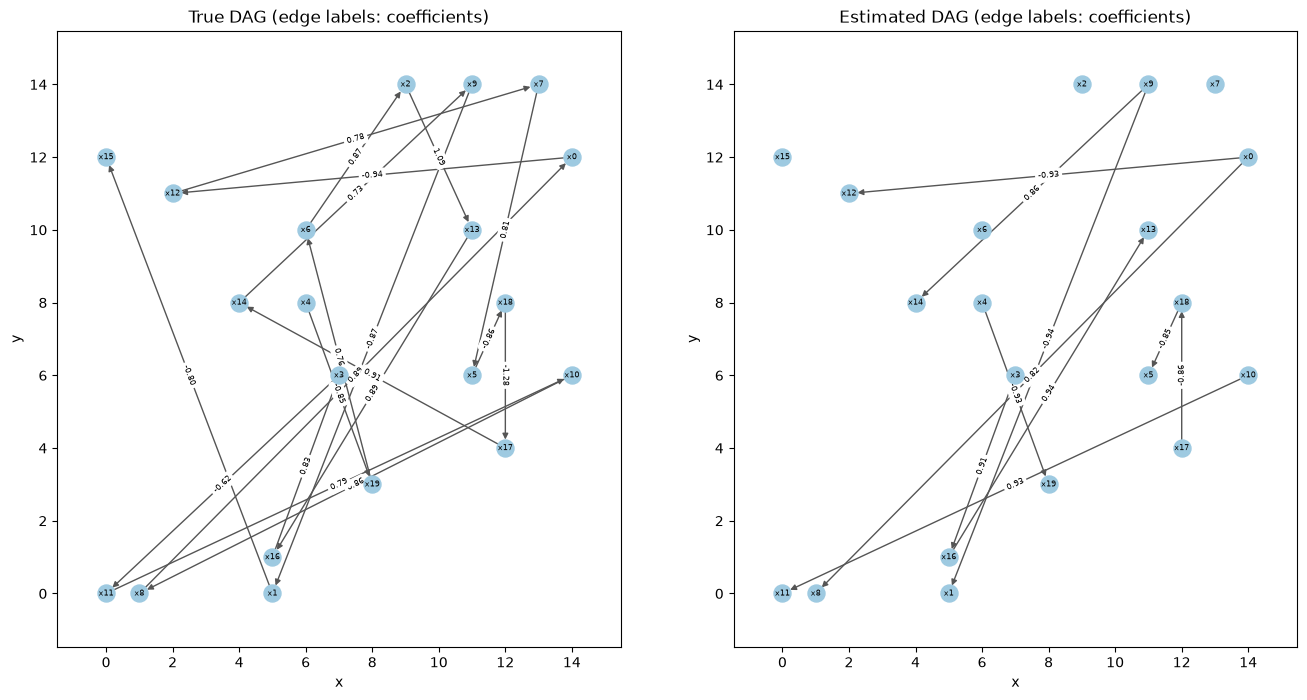

In [5]:
n_panels = 1 if B_true is None else 2
fig, axes = plt.subplots(1, n_panels, figsize=(8 * n_panels, 8), squeeze=False)
plot_dag(B_est, coords, edge_labels=B_est, ax=axes[0, -1], title="Estimated DAG (edge labels: coefficients)")
if B_true is not None:
    plot_dag(B_true, coords, edge_labels=B_true, ax=axes[0, 0], title="True DAG (edge labels: coefficients)")
plt.show()

## Network Metrics

Network metrics computed from the estimated DAG `B_est` and its causal order. 

| Column | Meaning |
|---|---|
| `causal_order` | Position in the estimated causal order (0 = most upstream). |
| `in_degree` | Number of direct parents (incoming edges). |
| `out_degree` | Number of direct children (outgoing edges). |
| `weighted_in_degree` | Sum of the absolute coefficients of incoming edges. |
| `weighted_out_degree` | Sum of the absolute coefficients of outgoing edges. |
| `ancestor_count` | Number of variables that reach this variable through directed paths (direct and indirect causes). |
| `descendant_count` | Number of variables reachable from this variable through directed paths (direct and indirect effects). |


In [6]:
metrics = network_metrics(B_est, order_est)
metrics.sort_values("causal_order")

,variable,causal_order,in_degree,out_degree,weighted_in_degree,weighted_out_degree,ancestor_count,descendant_count
17,x17,0,0,1,0.000000,0.863843,0,2
18,x18,1,1,1,0.863843,0.852988,1,1
2,x2,2,0,0,0.000000,0.000000,0,0
10,x10,3,0,1,0.000000,0.930356,0,1
11,x11,4,1,0,0.930356,0.000000,1,0
6,x6,5,0,0,0.000000,0.000000,0,0
3,x3,6,0,1,0.000000,0.910918,0,2
16,x16,7,1,1,0.910918,0.943941,1,1
7,x7,8,0,0,0.000000,0.000000,0,0
4,x4,9,0,1,0.000000,0.932283,0,1


## Bootstrap

In [7]:
boot = bootstrap(X, CONFIG["n_boot"], CONFIG["pc_alpha"], CONFIG["seed"], CONFIG["ci_level"], CONFIG["lingam_params"])
print(f"Successful iterations: {boot['n_success']}, failed: {boot['n_failed']}")

Bootstrap: 100%|██████████| 100/100 [03:05<00:00,  1.86s/it]


Successful iterations: 100, failed: 0


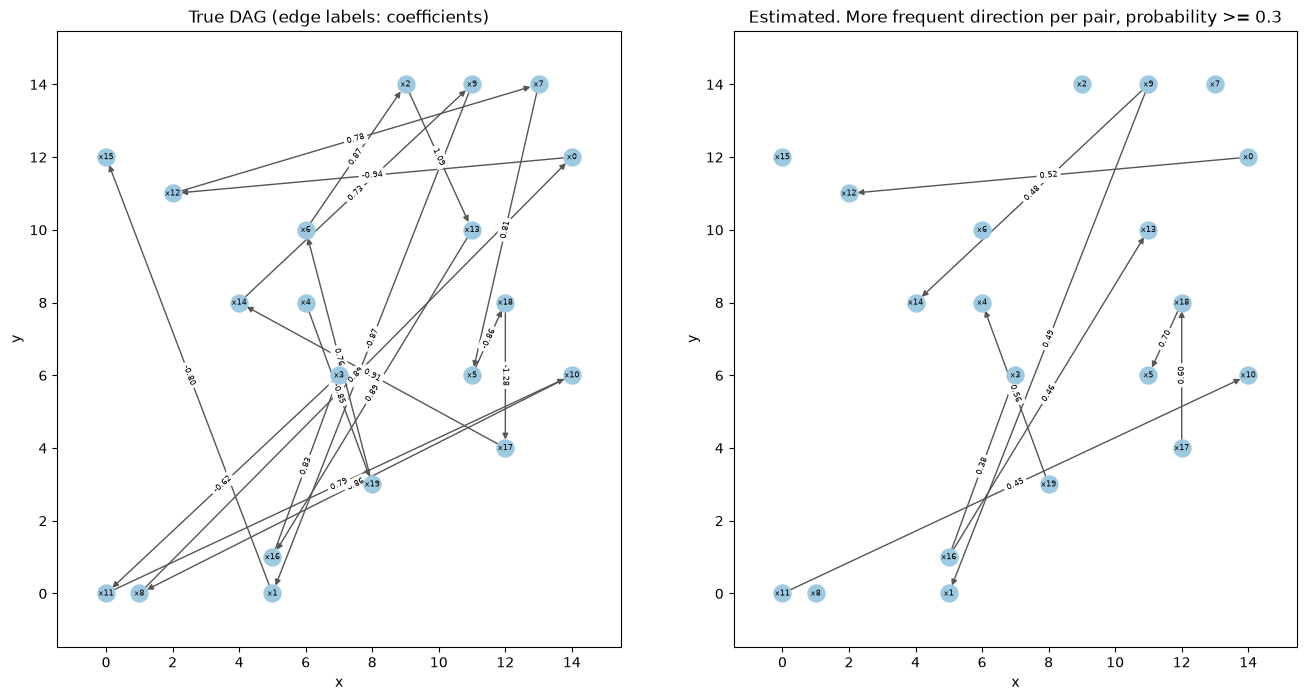

In [8]:
boot_dag = select_bootstrap_edges(boot["prob"], CONFIG["boot_edge_threshold"])
n_panels = 1 if B_true is None else 2
fig, axes = plt.subplots(1, n_panels, figsize=(8 * n_panels, 8), squeeze=False)
plot_dag(
    boot_dag, coords, edge_labels=boot_dag, ax=axes[0, -1],
    title=f"Estimated. More frequent direction per pair, probability >= {CONFIG['boot_edge_threshold']}",
)
if B_true is not None:
    plot_dag(B_true, coords, edge_labels=B_true, ax=axes[0, 0], title="True DAG (edge labels: coefficients)")
plt.show()

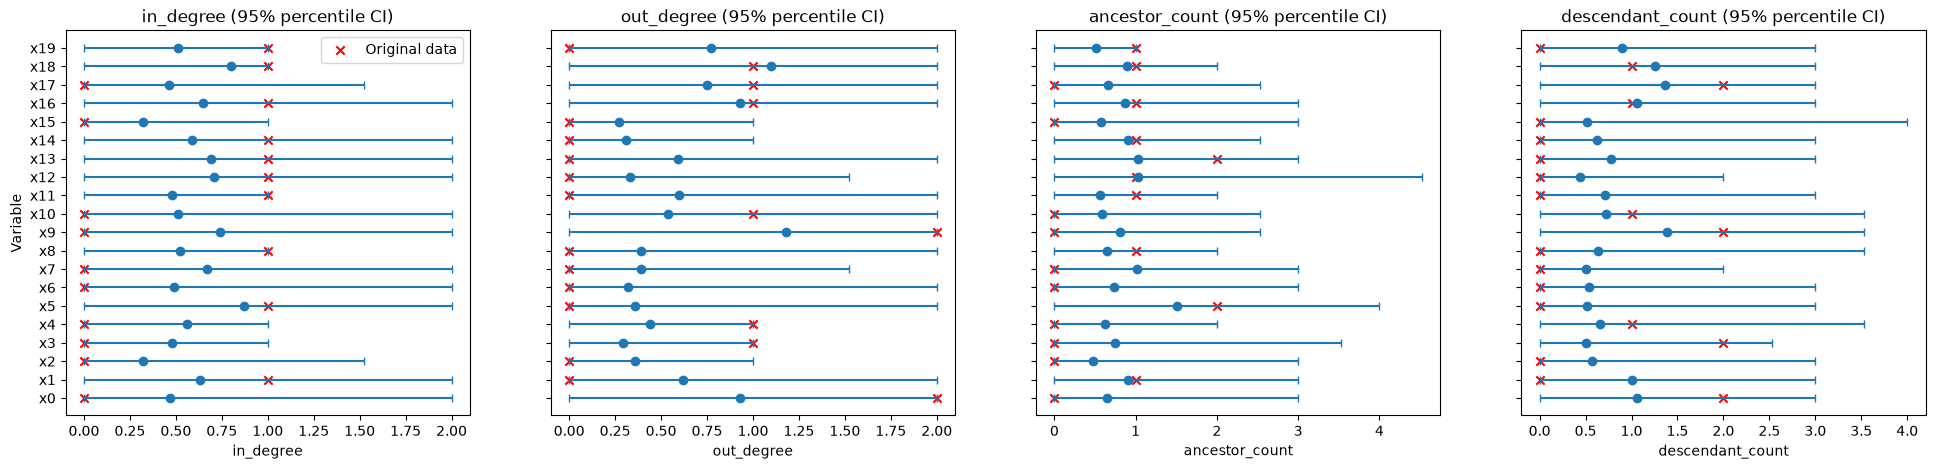

In [9]:
ci_metrics = ["in_degree", "out_degree", "ancestor_count", "descendant_count"]
fig, axes = plt.subplots(1, len(ci_metrics), figsize=(6 * len(ci_metrics), 5), sharey=True)
for ax, metric in zip(axes, ci_metrics):
    d = boot["metrics_ci"].query("metric == @metric").set_index("variable").loc[X.columns]
    ax.errorbar(d["mean"], range(len(d)), xerr=[d["mean"] - d["lower"], d["upper"] - d["mean"]], fmt="o", capsize=3)
    ax.scatter(metrics.set_index("variable").loc[X.columns, metric], range(len(d)), marker="x", color="red", label="Original data")
    ax.set_title(f"{metric} ({CONFIG['ci_level']:.0%} percentile CI)")
    ax.set_xlabel(metric)
axes[0].set_yticks(range(len(X.columns)), X.columns)
axes[0].set_ylabel("Variable")
axes[0].legend()
plt.show()